## Daftar Isi

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Import Libraries](#0)<br>
2.  [Fetching Data](#1) <br>
3.  [Area Plots](#6) <br>
4.  [Histograms](#8) <br>
5.  [Bar Charts](#10) <br>

</div>

# Import Libraries<a id="0"></a>


Impor pustaka `matplotlib`.

In [1]:
# Import Pustaka Utama
import pandas as pd
import numpy as np

# Gunakan backend inline untuk menghasilkan plot di dalam browser.
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
# Opsional: untuk penggunaan gaya seperti ggplot
mpl.style.use("ggplot")

In [3]:
# Cek versi dari matplotlib
print("Versi matplotlib:", mpl.__version__)

Versi matplotlib: 3.11.2


# Fetching Data<a id="1"></a>

Dataset: Imigrasi ke Kanada dari tahun 1980 hingga 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's 

Dalam lab ini, data yang digunakan akn berfokus pada Imigrasi Kanada dan menggunakan **dataset yang sudah dibersihkan** dan dapat diunduh dari <a href="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv">disini</a>.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk penyegaran cepat keterampilan Pandas, melalui [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/june2023_updates/Module%201/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)


In [4]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")
print("Data dibaca ke dalam dataframe pandas!")

Data dibaca ke dalam dataframe pandas!


Lihat lima data teratas pada dataset.

In [5]:
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Cari tahu berapa banyak entri yang ada dalam dataset.

In [6]:
print(df_canada.shape)

(195, 39)


Tetapkan nama negara sebagai indeks - berguna untuk mencari negara dengan cepat menggunakan metode .loc.

In [7]:
df_canada.set_index("Country", inplace=True)

In [8]:
# Hapus nama kolom indeks "Country"
df_canada.index.name = None

In [9]:
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Perhatikan bahwa nama-nama negara sekarang berfungsi sebagai indeks.

In [10]:
print("data dimensions:", df_canada.shape)

data dimensions: (195, 38)


In [11]:
# Terakhir, buat daftar tahun dari 1980 - 2013
# Ini akan berguna saat kita mulai memplot data

years = list(map(str, range(1980, 2014)))
years

['1980',
 '1981',
 '1982',
 '1983',
 '1984',
 '1985',
 '1986',
 '1987',
 '1988',
 '1989',
 '1990',
 '1991',
 '1992',
 '1993',
 '1994',
 '1995',
 '1996',
 '1997',
 '1998',
 '1999',
 '2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013']

# Area Plots<a id="6"></a>


Pada modul terakhir, kita telah membuat line plot yang memvisualisasikan 5 negara teratas yang menyumbang imigran terbanyak ke Kanada dari tahun 1980 hingga 2013. Dengan sedikit modifikasi pada kode, kita dapat memvisualisasikan plot ini sebagai plot kumulatif, yang juga dikenal sebagai **Stacked Line Plot** atau **Area Plot**.

In [12]:
df_canada.sort_values("Total", ascending=False, axis=0, inplace=True)

# Buat dataframe imigran dari 5 negara teratas
df_top5 = df_canada.head()

# Transpose dataframe agar indeksnya dari rentang tahun
df_top5 = df_top5[years].transpose()

# Cek hasil df_top5
df_top5.head()

,India,China,United Kingdom of Great Britain and Northern Ireland,Philippines,Pakistan
1980,8880,5123,22045,6051,978
1981,8670,6682,24796,5921,972
1982,8147,3308,20620,5249,1201
1983,7338,1863,10015,4562,900
1984,5704,1527,10170,3801,668


Are plot secara default ditumpuk. Dan untuk menghasilkan plot area bertumpuk, setiap kolom harus berisi nilai positif seluruhnya atau nilai negatif seluruhnya (nilai `NaN`, yaitu bukan angka, akan bernilai 0 secara default). Untuk menghasilkan plot yang tidak bertumpuk, atur parameter `stacked` ke nilai `False`.

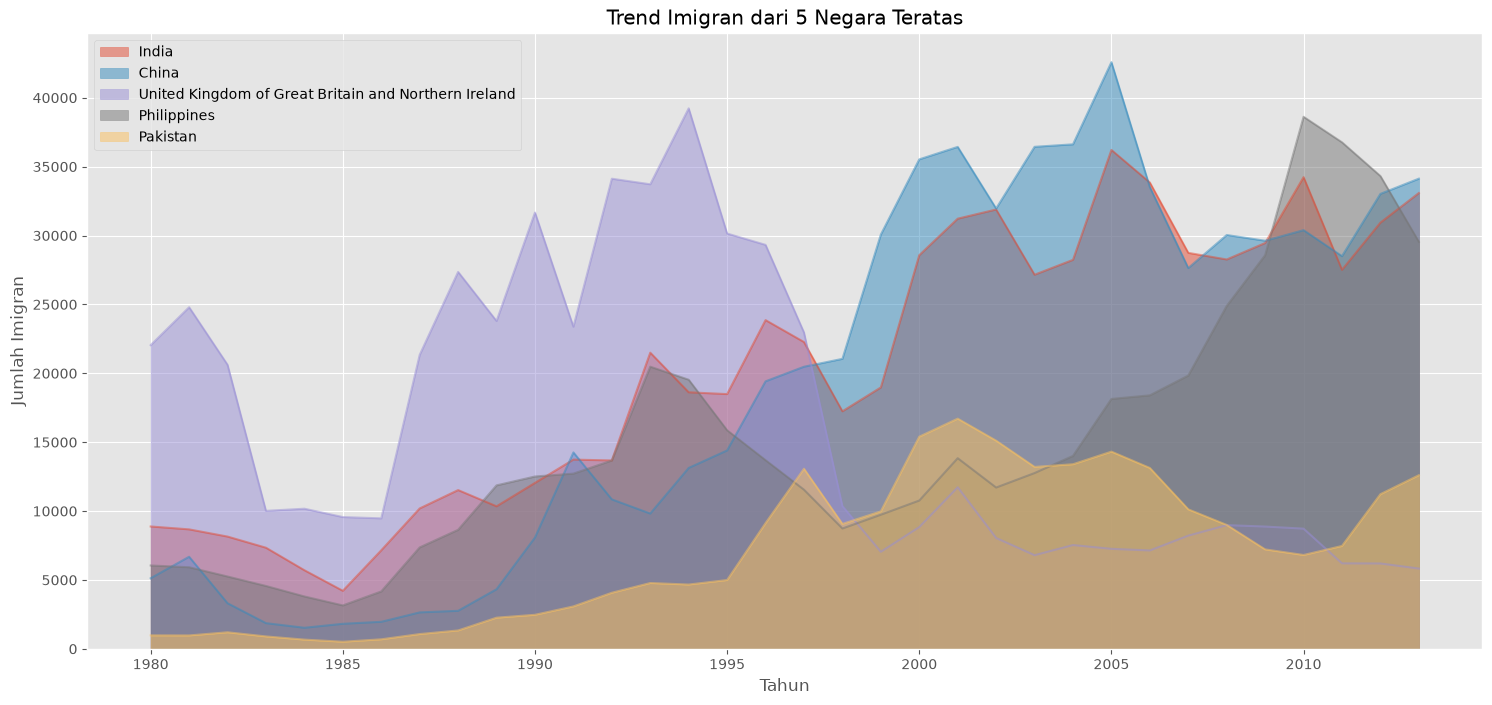

In [13]:
# Mari kita ubah nilai indeks df_top5 menjadi tipe integer untuk keperluan plotting.
df_top5.index = df_top5.index.map(int)

df_top5.plot(kind="area",
             stacked=False,
            figsize=(18, 8))

plt.title("Trend Imigran dari 5 Negara Teratas")
plt.ylabel("Jumlah Imigran")
plt.xlabel("Tahun")

plt.savefig("../outputs/area_plot_imigrasi_teratas.png",
           dpi=200, bbox_inches="tight")
plt.show()

Plot yang tidak ditumpuk (unstacked) memiliki transparansi (nilai alpha) default sebesar 0,5. Kita dapat mengubah nilai ini dengan memberikan parameter `alpha`.

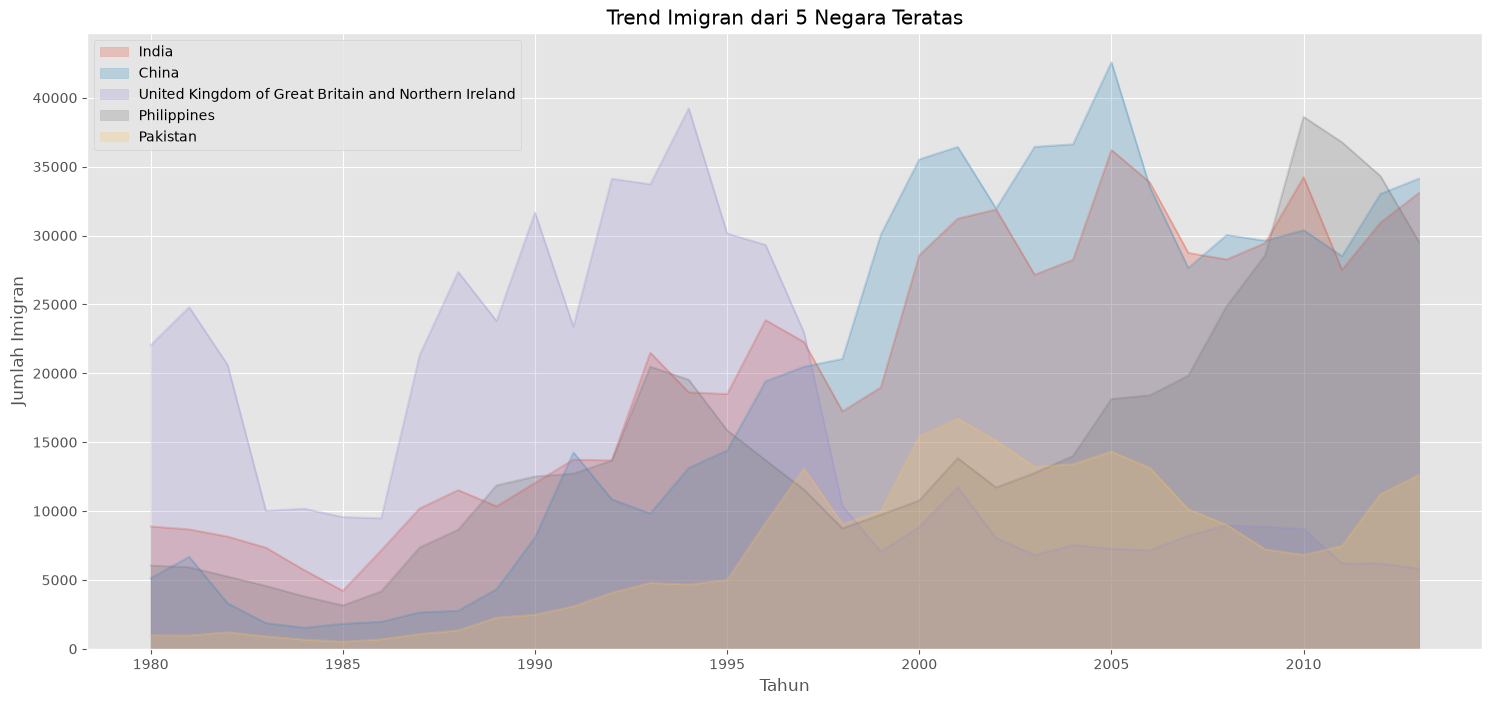

In [14]:
df_top5.plot(kind="area", alpha=0.25, # default 0.5
             stacked=False, figsize=(18, 8))

plt.title("Trend Imigran dari 5 Negara Teratas")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Imigran")

plt.savefig("../outputs/area_plot_imigrasi_teratas_025.png",
           dpi=200, bbox_inches="tight")
plt.show()

### Two types of plotting

Ada dua gaya/opsi plotting dengan `matplotlib`, yaitu plotting menggunakan layer Artist dan plotting menggunakan layer scripting.

**Opsi 1: Layer Scripting (metode prosedural) - menggunakan matplotlib.pyplot sebagai 'plt'**

Anda dapat menggunakan `plt` yaitu `matplotlib.pyplot` dan menambahkan lebih banyak elemen dengan memanggil berbagai metode secara prosedural; misalnya, `plt.title(...)` untuk menambahkan judul atau `plt.xlabel(...)` untuk menambahkan label pada sumbu x.

```python
# Opsi 1: Ini yang telah kita gunakan sejauh ini
df_top5.plot(kind='area', alpha=0.35, figsize=(20, 10))
plt.title('Tren imigrasi 5 negara teratas')
plt.ylabel('Jumlah imigran')
plt.xlabel('Tahun')

**Opsi 2: Lapisan Artist (Metode berorientasi objek) - menggunakan instance `Axes` dari Matplotlib (lebih disukai)**

Anda dapat menggunakan instance `Axes` dari plot Anda saat ini dan menyimpannya dalam variabel (misalnya, `ax`). Anda dapat menambahkan lebih banyak elemen dengan memanggil metode dengan sedikit perubahan sintaks (dengan menambahkan "`set_`" ke metode sebelumnya). Misalnya, gunakan `ax.set_title()` sebagai pengganti `plt.title()` untuk menambahkan judul, atau `ax.set_xlabel()` sebagai pengganti `plt.xlabel()` untuk menambahkan label ke sumbu x.

Opsi ini terkadang lebih transparan dan fleksibel untuk digunakan pada plot tingkat lanjut (khususnya ketika memiliki beberapa plot, seperti yang akan Anda lihat nanti).

Dalam kursus ini, kita akan tetap menggunakan **lapisan skrip**, kecuali untuk beberapa visualisasi tingkat lanjut di mana kita perlu menggunakan **lapisan artist** untuk memanipulasi aspek-aspek tingkat lanjut dari plot.

Text(0.5, 0, 'Tahun')

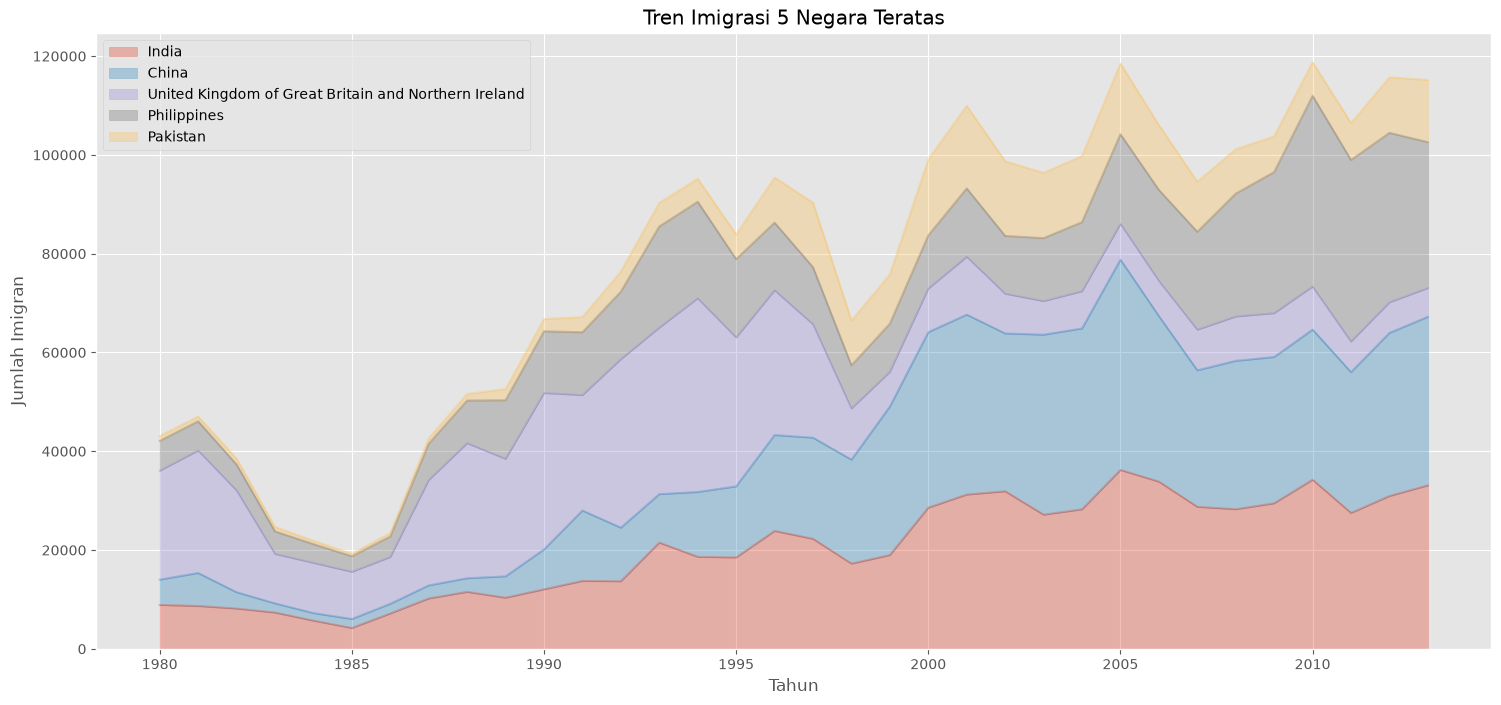

In [15]:
# Contoh penggunaan lapisan Artist
ax = df_top5.plot(kind="area", alpha=0.35, figsize=(18, 8))

ax.set_title("Tren Imigrasi 5 Negara Teratas")
ax.set_ylabel("Jumlah Imigran")
ax.set_xlabel("Tahun")

**Pertanyaan**: Gunakan lapisan skrip untuk membuat plot area bertumpuk (stacked) dari 5 negara yang paling sedikit berkontribusi terhadap imigrasi ke Kanada **dari** tahun 1980 hingga 2013. Gunakan nilai transparansi 0,45.

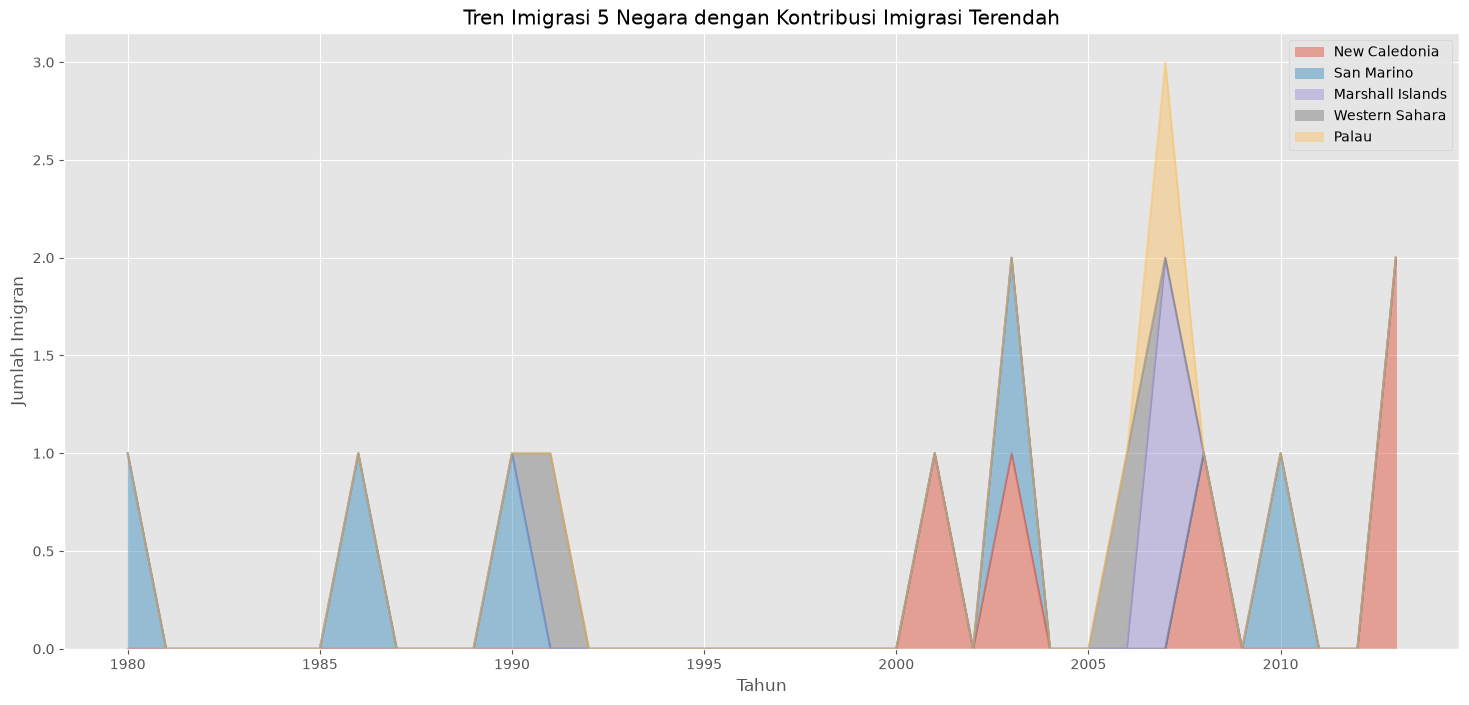

In [16]:
# Temukan 5 negara dengan sedikit kontribusi (5 terbawah) 
df_least5 = df_canada.tail()
df_least5 = df_least5[years].transpose()
df_least5.head()

# Ubah index menjadi int
df_least5.index = df_least5.index.map(int)

# Buat area plot menggunakan lapisan script
df_least5.plot(kind="area", alpha=0.45, figsize=(18, 8))

plt.title("Tren Imigrasi 5 Negara dengan Kontribusi Imigrasi Terendah")
plt.ylabel("Jumlah Imigran")
plt.xlabel("Tahun")

plt.savefig("../outputs/area_plot_imigrasi_terendah.png", dpi=200, bbox_inches="tight")
plt.show()

**Pertanyaan**: Gunakan lapisan artis untuk membuat plot area yang tidak bertumpuk dari 5 negara yang paling sedikit berkontribusi terhadap imigrasi ke Kanada **dari** tahun 1980 hingga 2013. Gunakan nilai transparansi 0,55.


Text(0.5, 0, 'Tahun')

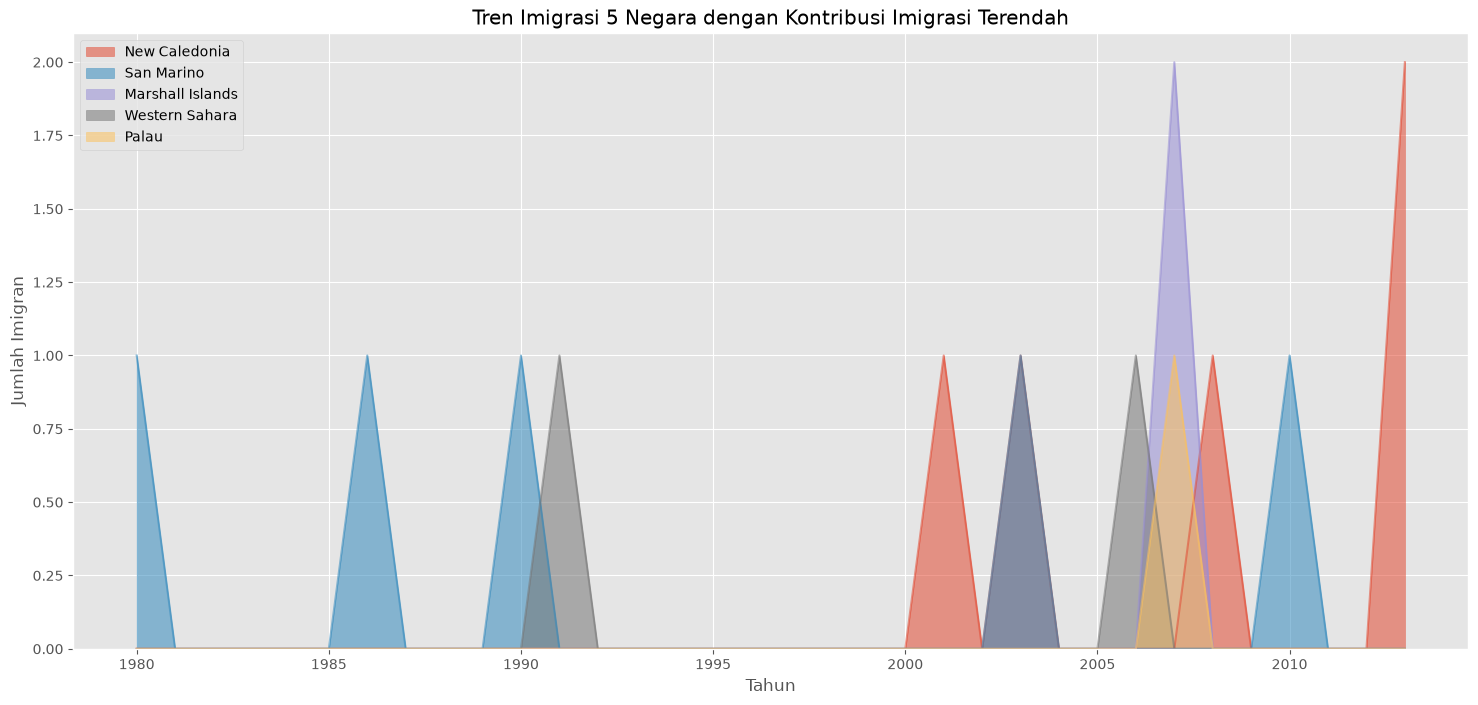

In [17]:
# Buat area plot menggunakan lapisan artist
ax = df_least5.plot(kind="area", alpha=0.55, stacked=False, figsize=(18, 8))
ax.set_title("Tren Imigrasi 5 Negara dengan Kontribusi Imigrasi Terendah")
ax.set_ylabel("Jumlah Imigran")
ax.set_xlabel("Tahun")

# Histograms<a id="8"></a>

Histogram adalah cara untuk merepresentasikan distribusi *frekuensi* dari dataset numerik. Cara kerjanya adalah dengan membagi sumbu x menjadi *bin*, menetapkan setiap titik data dalam dataset kita ke dalam sebuah bin, dan kemudian menghitung jumlah titik data yang telah ditetapkan ke setiap bin. Jadi sumbu y adalah frekuensi atau jumlah titik data di setiap bin. Perhatikan bahwa kita dapat mengubah ukuran bin dan biasanya perlu disesuaikan agar distribusi ditampilkan dengan baik.


**Pertanyaan:** Berapakah distribusi frekuensi jumlah (populasi) imigran baru dari berbagai negara ke Kanada pada tahun 2013?

Sebelum kita melanjutkan pembuatan plot histogram, mari kita periksa terlebih dahulu data yang dibagi menjadi beberapa interval. Untuk melakukan ini, kita akan menggunakan metode `histogram` dari **Numpy** untuk mendapatkan rentang bin dan jumlah frekuensi sebagai berikut:



In [18]:
# Cek terlebih dahulu data imigran tahun 2013
df_canada["2013"].head()

India                                                   33087
China                                                   34129
United Kingdom of Great Britain and Northern Ireland     5827
Philippines                                             29544
Pakistan                                                12603
Name: 2013, dtype: int64

In [19]:
# metode np.histogram menghasilkan 2 output
count, bin_edges = np.histogram(df_canada["2013"])

print(count) # menghitung frekuensi
print(bin_edges) # rentang bin, default=10

[178  11   1   2   0   0   0   0   1   2]
[    0.   3412.9  6825.8 10238.7 13651.6 17064.5 20477.4 23890.3 27303.2
 30716.1 34129. ]


Secara default, metode `histogram` membagi dataset menjadi 10 bin. Gambar di bawah ini merangkum rentang bin dan distribusi frekuensi imigrasi pada tahun 2013. Kita dapat melihat bahwa pada tahun 2013:

*   178 negara menyumbang antara 0 hingga 3412,9 imigran.
*   11 negara menyumbang antara 3412,9 hingga 6825,8 imigran.
*   Satu negara menyumbang antara 6285,8 hingga 10238,7 imigran, dan seterusnya.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%202/images/Mod2Fig1-Histogram.jpg" align="center" width="800">


Kita dapat dengan mudah membuat grafik distribusi ini dengan memberikan `kind=hist` ke `plot()`.

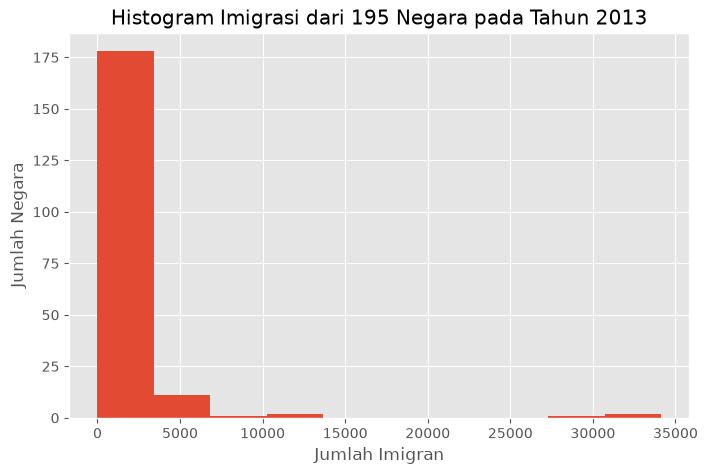

In [20]:
df_canada["2013"].plot(kind="hist", figsize=(8, 5))

plt.title("Histogram Imigrasi dari 195 Negara pada Tahun 2013")
plt.ylabel("Jumlah Negara")
plt.xlabel("Jumlah Imigran")

plt.show()

Pada grafik di atas, sumbu x mewakili rentang populasi imigran dalam interval 3412,9. Sumbu y mewakili jumlah negara yang berkontribusi pada populasi tersebut.

Perhatikan bahwa label sumbu x tidak sesuai dengan ukuran bin. Ini dapat diperbaiki dengan memasukkan kata kunci `xticks` yang berisi daftar ukuran bin, sebagai berikut:

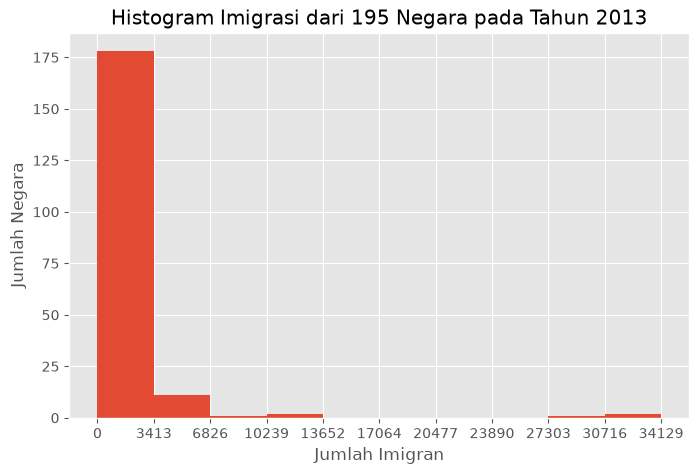

In [21]:
# 'bin_edges' adalah daftar interval bin.
count, bin_edges = np.histogram(df_canada["2013"])

df_canada["2013"].plot(kind="hist", figsize=(8, 5), xticks=bin_edges)

plt.title("Histogram Imigrasi dari 195 Negara pada Tahun 2013")
plt.ylabel("Jumlah Negara")
plt.xlabel("Jumlah Imigran")

plt.savefig("../outputs/histogram_imigrasi_2013.png", dpi=200,
           bbox_inches="tight")
plt.show()

*Catatan Tambahan:* Kita bisa menggunakan `df_can['2013'].plot.hist()` sebagai gantinya. Bahkan, sepanjang pelajaran ini, menggunakan `some_data.plot(kind='type_plot', ...)` setara dengan `some_data.plot.type_plot(...)`. Artinya, meneruskan tipe plot sebagai argumen atau metode akan berperilaku sama.

Lihat dokumentasi *pandas* untuk informasi selengkapnya.  [http://pandas.pydata.org/pandas-docs/stable/generated/pandas.Series.plot.html](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.Series.plot.html?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01).


Kita juga dapat membuat beberapa histogram pada grafik yang sama. Misalnya, mari kita coba menjawab pertanyaan-pertanyaan berikut menggunakan histogram.

**Pertanyaan**: Bagaimana distribusi imigrasi untuk Denmark, Norway, dan Sweden untuk tahun 1980 - 2013?

In [22]:
# Lihat dulu datasetnya
df_canada.loc[["Denmark", "Norway", "Sweden"], years]

,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
Denmark,272,293,299,106,93,73,93,109,129,129,...,89,62,101,97,108,81,92,93,94,81
Norway,116,77,106,51,31,54,56,80,73,76,...,73,57,53,73,66,75,46,49,53,59
Sweden,281,308,222,176,128,158,187,198,171,182,...,129,205,139,193,165,167,159,134,140,140


<Axes: ylabel='Frequency'>

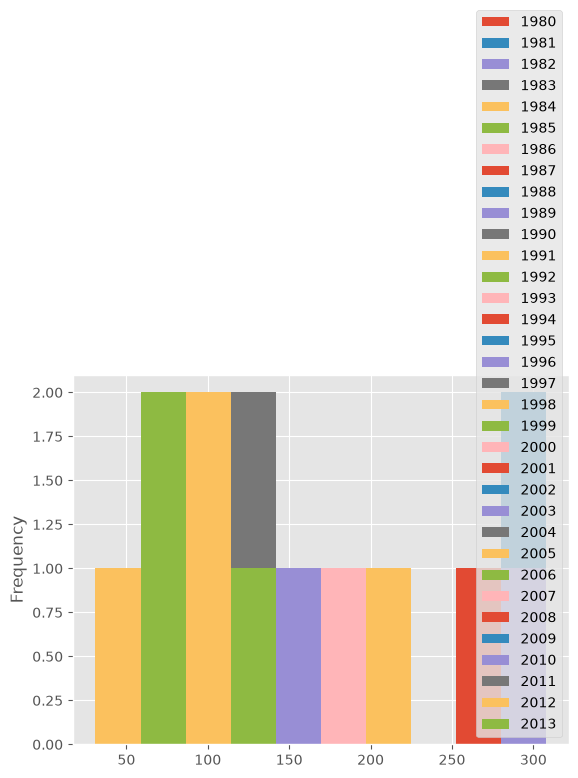

In [23]:
# Buatkan plot histogram
df_canada.loc[["Denmark", "Norway", "Sweden"], years].plot.hist()

Itu terlihat tidak benar!

Jangan khawatir, Anda akan sering menemukan situasi seperti ini saat membuat plot. Solusinya seringkali terletak pada bagaimana struktur dataset yang mendasarinya.

Alih-alih memplot distribusi frekuensi populasi untuk 3 negara, *pandas* malah memplot distribusi frekuensi populasi untuk `tahun`.

Ini dapat dengan mudah diperbaiki dengan terlebih dahulu mentranspos dataset, lalu memplot seperti yang ditunjukkan di bawah ini.

In [24]:
# Lakukan transpose pada dataset
df_dns = df_canada.loc[["Denmark", "Norway", "Sweden"], years].transpose()

In [25]:
# Cek dataset
df_dns.head()

,Denmark,Norway,Sweden
1980,272,116,281
1981,293,77,308
1982,299,106,222
1983,106,51,176
1984,93,31,128


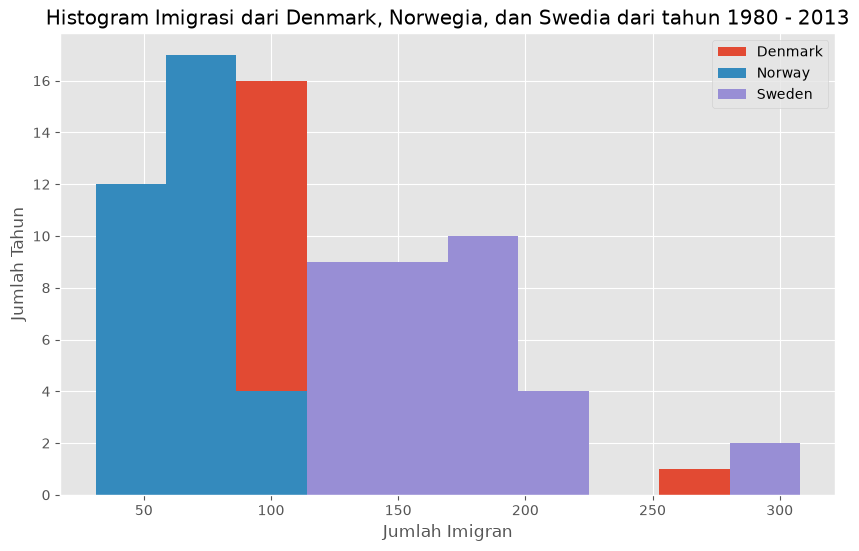

In [26]:
# Buat plot histogram
df_dns.plot(kind="hist", figsize=(10, 6))

plt.title("Histogram Imigrasi dari Denmark, Norwegia, dan Swedia dari tahun 1980 - 2013")
plt.ylabel("Jumlah Tahun")
plt.xlabel("Jumlah Imigran")

plt.show()

Mari kita lakukan beberapa modifikasi untuk meningkatkan dampak dan estetika dari alur cerita sebelumnya:

*   Tingkatkan ukuran bin menjadi 15 dengan memberikan parameter `bins`;
*   Atur transparansi menjadi 60% dengan memasukkan parameter `alpha`;
*   Beri label pada sumbu x dengan memasukkan parameter `x-label`;
*   Ubah warna plot dengan memberikan parameter `color`.

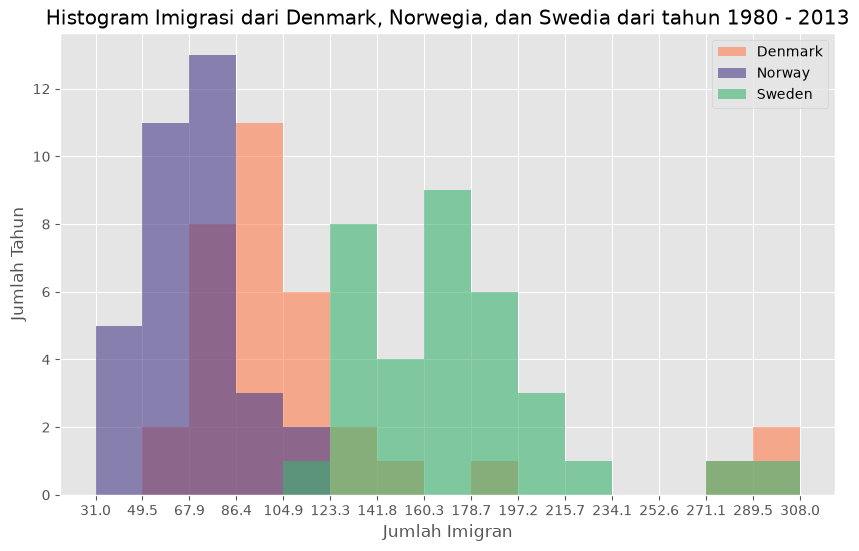

In [27]:
# cari nilai x-ticks
count, bin_edges = np.histogram(df_dns, 15)

# unstacked histogram
df_dns.plot(kind="hist", figsize=(10, 6), bins=15, 
            alpha=0.6, xticks=bin_edges,
            color=['coral', 'darkslateblue', 'mediumseagreen'])

plt.title("Histogram Imigrasi dari Denmark, Norwegia, dan Swedia dari tahun 1980 - 2013")
plt.ylabel("Jumlah Tahun")
plt.xlabel("Jumlah Imigran")


plt.savefig("../outputs/unstacked_histogram_imigrasi_denmark_norway_sweden.png",
           dpi=200, bbox_inches="tight")
plt.show()

Tip:
Untuk daftar lengkap warna yang tersedia di Matplotlib, jalankan kode berikut di shell python Anda:

```python
import matplotlib
for name, hex in matplotlib.colors.cnames.items():
    print(name, hex)
```

In [28]:
for name, hex, in mpl.colors.cnames.items():
    print(name, hex)

aliceblue #F0F8FF
antiquewhite #FAEBD7
aqua #00FFFF
aquamarine #7FFFD4
azure #F0FFFF
beige #F5F5DC
bisque #FFE4C4
black #000000
blanchedalmond #FFEBCD
blue #0000FF
blueviolet #8A2BE2
brown #A52A2A
burlywood #DEB887
cadetblue #5F9EA0
chartreuse #7FFF00
chocolate #D2691E
coral #FF7F50
cornflowerblue #6495ED
cornsilk #FFF8DC
crimson #DC143C
cyan #00FFFF
darkblue #00008B
darkcyan #008B8B
darkgoldenrod #B8860B
darkgray #A9A9A9
darkgreen #006400
darkgrey #A9A9A9
darkkhaki #BDB76B
darkmagenta #8B008B
darkolivegreen #556B2F
darkorange #FF8C00
darkorchid #9932CC
darkred #8B0000
darksalmon #E9967A
darkseagreen #8FBC8F
darkslateblue #483D8B
darkslategray #2F4F4F
darkslategrey #2F4F4F
darkturquoise #00CED1
darkviolet #9400D3
deeppink #FF1493
deepskyblue #00BFFF
dimgray #696969
dimgrey #696969
dodgerblue #1E90FF
firebrick #B22222
floralwhite #FFFAF0
forestgreen #228B22
fuchsia #FF00FF
gainsboro #DCDCDC
ghostwhite #F8F8FF
gold #FFD700
goldenrod #DAA520
gray #808080
green #008000
greenyellow #ADFF2F


Jika kita tidak ingin plot saling tumpang tindih (overlap), kita dapat menumpuknya menggunakan parameter `stacked`. Mari kita juga sesuaikan label sumbu x `min` dan `max` untuk menghilangkan celah tambahan di tepi plot. Kita dapat memberikan tuple (min, max) menggunakan parameter `xlim`, seperti yang ditunjukkan di bawah ini.

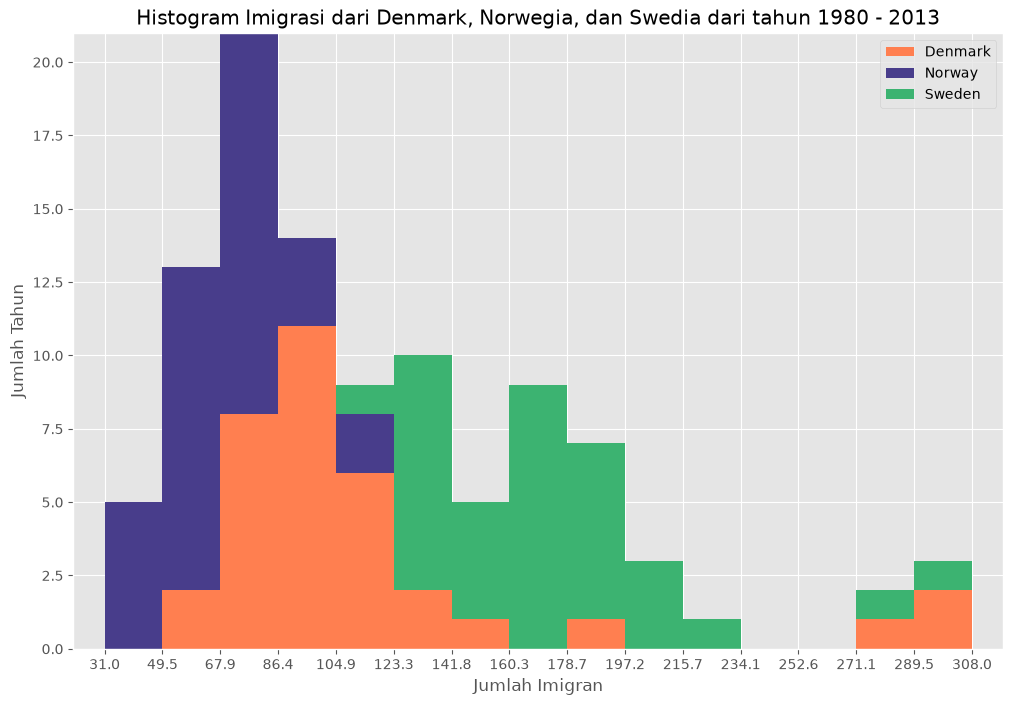

In [29]:
count, bin_edges = np.histogram(df_dns, 15)
xmin = bin_edges[0] - 10 # Nilai bin pertama adalah 31,0, menambahkan buffer 10 untuk tujuan estetika.
xmax = bin_edges[-1] + 10 # Nilai bin terakhir adalah 308,0, menambahkan buffer 10 untuk tujuan estetika.

# stacked histogram
df_dns.plot(kind="hist", figsize=(12, 8), bins=15, xticks=bin_edges,
           color=["coral", "darkslateblue", "mediumseagreen"],
           stacked=True, xlim=(xmin, xmax))

plt.title("Histogram Imigrasi dari Denmark, Norwegia, dan Swedia dari tahun 1980 - 2013")
plt.ylabel("Jumlah Tahun")
plt.xlabel("Jumlah Imigran")


plt.savefig("../outputs/stacked_histogram_imigrasi_denmark_norway_sweden.png",
           dpi=200, bbox_inches="tight")
plt.show()

**Pertanyaan**: Gunakan lapisan skrip untuk menampilkan distribusi imigrasi untuk Greece, Albania, and Bulgaria untuk tahun 1980 - 2013? Gunakan plot tumpang tindih dengan 15 bin dan nilai transparansi 0,35.

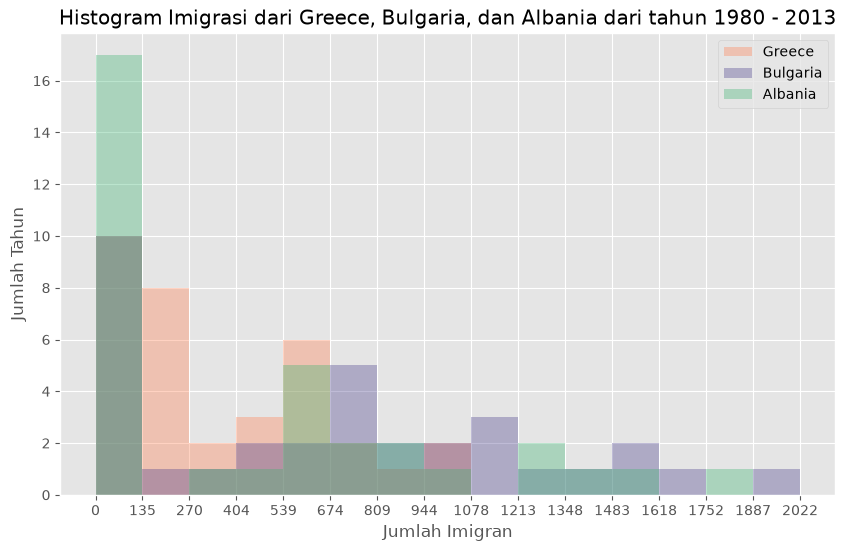

In [30]:
# Buat dataframe negara-negara yang diminati / countries of interest (cof).
df_gba = df_canada.loc[["Greece", "Bulgaria", "Albania"], years]

# Transpose dataframe
df_gba = df_gba.transpose()

# Buat perhitungan frekuensi dan bins
count, bin_edges = np.histogram(df_gba, 15)

# Buat unstacked histogram
df_gba.plot(kind="hist", figsize=(10, 6), bins=15,
           xticks=bin_edges, alpha=0.35,
           color=["coral", "darkslateblue", "mediumseagreen"])

plt.title("Histogram Imigrasi dari Greece, Bulgaria, dan Albania dari tahun 1980 - 2013")
plt.ylabel("Jumlah Tahun")
plt.xlabel("Jumlah Imigran")

plt.savefig("../outputs/unstacked_histogram_imigrasi_greece_bulgaria_albania.png")
plt.show()

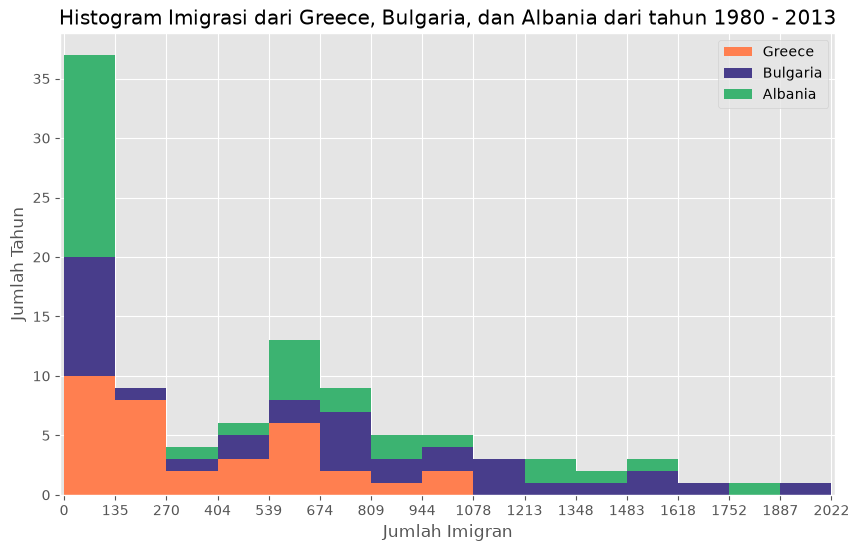

In [31]:
count, bin_edges = np.histogram(df_gba, 15)
xmin = bin_edges[0] - 10
xmax = bin_edges[-1] + 10

# stacked histogram
df_gba.plot(kind="hist", figsize=(10, 6), bins=15, xticks=bin_edges,
           stacked=True, xlim=(xmin, xmax), color=["coral", "darkslateblue", "mediumseagreen"])

plt.title("Histogram Imigrasi dari Greece, Bulgaria, dan Albania dari tahun 1980 - 2013")
plt.ylabel("Jumlah Tahun")
plt.xlabel("Jumlah Imigran")

plt.savefig("../outputs/stacked_histogram_imigrasi_greece_bulgaria_albania.png",
           dpi=200, bbox_inches="tight")
plt.show()

# Bar Charts (Dataframe) <a id="10"></a>

Bar plot atau diagram batang adalah cara untuk merepresentasikan data di mana *length* batang mewakili besaran/ukuran fitur/variabel. Bar chart atau grafik batang biasanya merepresentasikan variabel numerik dan kategorikal yang dikelompokkan dalam interval.

Untuk membuat plot batang, kita dapat memberikan salah satu dari dua argumen melalui parameter `kind` di `plot()`:

*   `kind=bar` membuat plot batang *vertikal*
*   `kind=barh` membuat plot batang *horizontal*


**Grafik batang vertikal**

Pada grafik batang vertikal, sumbu x digunakan untuk pelabelan, dan panjang batang pada sumbu y sesuai dengan besarnya variabel yang diukur. Grafik batang vertikal sangat berguna dalam menganalisis data deret waktu. Salah satu kekurangannya adalah kurangnya ruang untuk pelabelan teks di bagian bawah setiap batang.

**Mari kita mulai dengan menganalisis dampak Krisis Keuangan Islandia:**

Krisis Keuangan Islandia 2008-2011 merupakan peristiwa ekonomi dan politik besar di Islandia. Dibandingkan dengan ukuran ekonominya, keruntuhan sistem perbankan Islandia adalah yang terbesar yang pernah dialami oleh negara mana pun dalam sejarah ekonomi. Krisis ini menyebabkan depresi ekonomi yang parah pada tahun 2008-2011 dan gejolak politik yang signifikan.

**Pertanyaan:** Mari kita bandingkan jumlah imigran Islandia (negara = 'Iceland') ke Kanada dari tahun 1980 hingga 2013.

In [32]:
# langkah 1: ambil datanya
df_iceland = df_canada.loc["Iceland", years]
df_iceland.head()

1980    17
1981    33
1982    10
1983     9
1984    13
Name: Iceland, dtype: int64

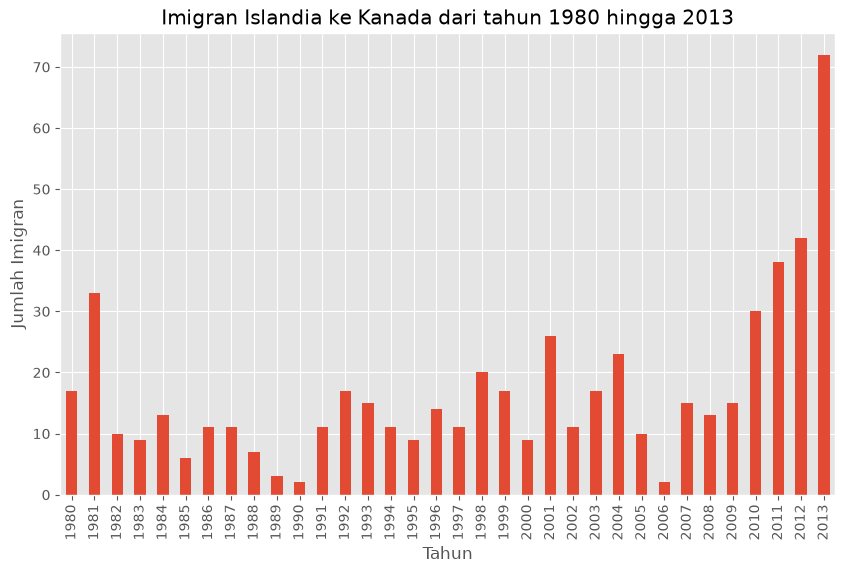

In [33]:
# langkah 2: buat plot data
df_iceland.plot(kind="bar", figsize=(10, 6))

plt.title("Imigran Islandia ke Kanada dari tahun 1980 hingga 2013")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Imigran")

plt.savefig("../outputs/bar_plot_imigrasi_iceland.png", dpi=200, bbox_inches="tight")
plt.show()

Grafik batang di atas menunjukkan jumlah total imigran yang dibagi berdasarkan setiap tahun. Kita dapat dengan jelas melihat dampak krisis keuangan; jumlah imigran ke Kanada mulai meningkat pesat setelah tahun 2008.

Mari kita beri anotasi pada plot menggunakan metode `annotate` dari **lapisan skrip** atau **antarmuka pyplot**. Kita akan memasukkan parameter berikut:

*   `s`: str, teks anotasi
*   `xy`: Tuple yang menentukan titik (x,y) yang akan diberi anotasi (dalam hal ini, titik akhir panah).
*   `xytext`: Tuple yang menentukan titik (x,y) tempat teks akan ditempatkan (dalam hal ini, titik awal panah).
*   `xycoords`: Sistem koordinat yang diberikan untuk xy - 'data' menggunakan sistem koordinat objek yang sedang dianotasi (default).
*   `arrowprops`: Menerima kamus properti untuk menggambar panah:
    *   `arrowstyle`: Menentukan gaya panah, `'->'` adalah panah standar.
    *   `connectionstyle`: Menentukan jenis koneksi. `arc3` adalah garis lurus.
    *   `color`: Menentukan warna panah.
    *   `lw`: Menentukan lebar garis.

Saya menyarankan Anda untuk membaca dokumentasi Matplotlib untuk detail lebih lanjut tentang anotasi:
<https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.annotate.html>.


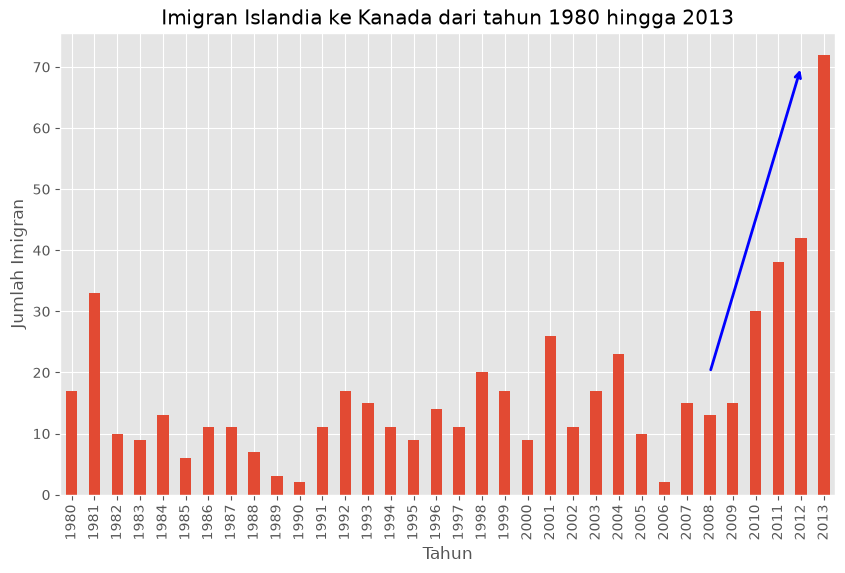

In [116]:
df_iceland.plot(kind="bar", figsize=(10, 6))

plt.title("Imigran Islandia ke Kanada dari tahun 1980 hingga 2013")
plt.ylabel("Jumlah Imigran")
plt.xlabel("Tahun")

# Annotate arrow
plt.annotate("", # s: str. Akan dibiarkan kosong jika tidak ada teks.
             xy=(32, 70), # letakkan ujung panah di titik (tahun 2012, populasi 70)
             xytext=(28, 20), # tempatkan pangkal panah di titik (tahun 2008, populasi 20)
             xycoords="data", # akan menggunakan sistem koordinat dari objek yang sedang diberi anotasi.
             arrowprops=dict(arrowstyle="->", connectionstyle="arc3", color="blue", lw=2)
            )

plt.savefig("../outputs/bar_arrow_imigrasi_iceland.png", dpi=200, bbox_inches="tight")
plt.show()

Mari kita tambahkan juga teks yang akan ditempatkan di atas panah. Kita akan memasukkan parameter tambahan berikut:

*   `rotation`: sudut rotasi teks dalam derajat (berlawanan arah jarum jam)
*   `va`: perataan teks vertikal \[‘center’ | ‘top’ | ‘bottom’ | ‘baseline’]
*   `ha`: perataan teks horizontal \[‘center’ | ‘right’ | ‘left’]

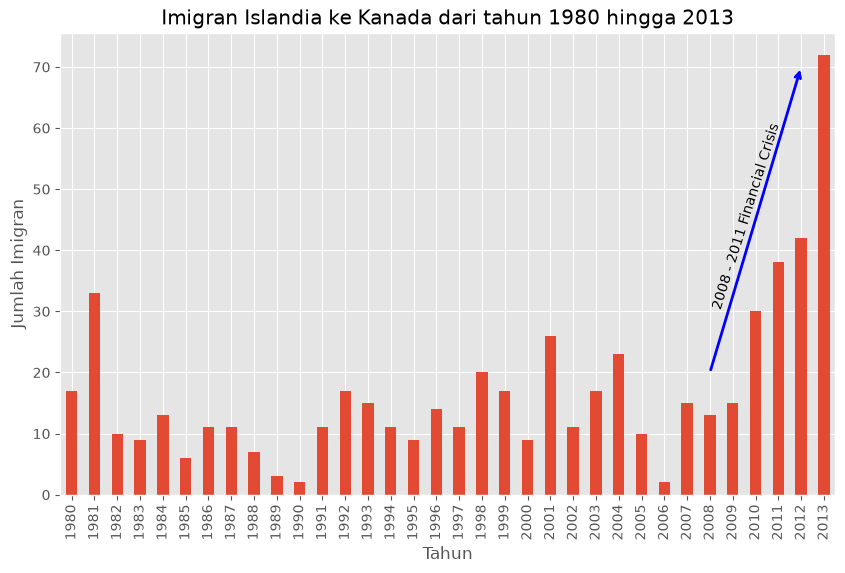

In [117]:
df_iceland.plot(kind="bar", figsize=(10, 6))

plt.title("Imigran Islandia ke Kanada dari tahun 1980 hingga 2013")
plt.ylabel("Jumlah Imigran")
plt.xlabel("Tahun")

# Annotate arrow
plt.annotate("", # s: str. Akan dibiarkan kosong jika tidak ada teks.
             xy=(32, 70), # letakkan ujung panah di titik (tahun 2012, populasi 70)
             xytext=(28, 20), # tempatkan pangkal panah di titik (tahun 2008, populasi 20)
             xycoords="data", # akan menggunakan sistem koordinat dari objek yang sedang diberi anotasi.
             arrowprops=dict(arrowstyle="->", connectionstyle="arc3", color="blue", lw=2)
            )

# Annotate text
plt.annotate("2008 - 2011 Financial Crisis", # teks yang ditampilkan
             xy=(28, 30), # mulai teks pada titik (tahun 2008, populasi 30)
             rotation=72.5, # berdasarkan coba-coba untuk mencocokkan panah
             va="bottom", # ingin teks tersebut sejajar secara vertikal di bagian bawah
             ha="left" # ingin teks tersebut rata kiri secara horizontal.
            )

plt.savefig("../outputs/bar_arrow_text_imigrasi_iceland.png", dpi=200, bbox_inches="tight")
plt.show()

**Horizontal Bar Plot**

Terkadang lebih praktis untuk merepresentasikan data secara horizontal, terutama jika Anda membutuhkan lebih banyak ruang untuk memberi label pada batang grafik. Pada grafik batang horizontal, sumbu y digunakan untuk memberi label, dan panjang batang pada sumbu x sesuai dengan besarnya variabel yang diukur. Seperti yang akan Anda lihat, ada lebih banyak ruang pada sumbu y untuk memberi label pada variabel kategorikal.

**Pertanyaan:** Dengan menggunakan skrip yang akan diberikan dan dataset `df_canada`, buatlah plot batang *horizontal* yang menunjukkan jumlah *total* imigran ke Kanada dari 15 negara teratas, untuk periode 1980 - 2013. Beri label pada setiap negara dengan jumlah total imigran.


Langkah 1: Dapatkan data yang berkaitan dengan 15 negara teratas.

In [36]:
# Ubah urutan dataframe yang awalnya descending menjadi ascending
df_canada.sort_values("Total", axis=0, ascending=True, inplace=True)

# Ambil data dengan total paling tinggi sebanyak 15 negara
# Gunakan tail karena urutannya naik
df_top15 = df_canada["Total"].tail(15)
df_top15

Romania                                                  93585
Viet Nam                                                 97146
Jamaica                                                 106431
France                                                  109091
Lebanon                                                 115359
Poland                                                  139241
Republic of Korea                                       142581
Sri Lanka                                               148358
Iran (Islamic Republic of)                              175923
United States of America                                241122
Pakistan                                                241600
Philippines                                             511391
United Kingdom of Great Britain and Northern Ireland    551500
China                                                   659962
India                                                   691904
Name: Total, dtype: int64

Langkah 2: Plot data:

1.  Gunakan `kind='barh'` untuk menghasilkan grafik batang dengan batang horizontal.
2.  Pastikan Anda memilih ukuran yang tepat untuk grafik dan memberi label pada sumbu serta memberi judul pada grafik tersebut.
3.  Lakukan perulangan melalui negara-negara dan beri anotasi pada populasi imigran menggunakan fungsi anotasi pada antarmuka skrip.


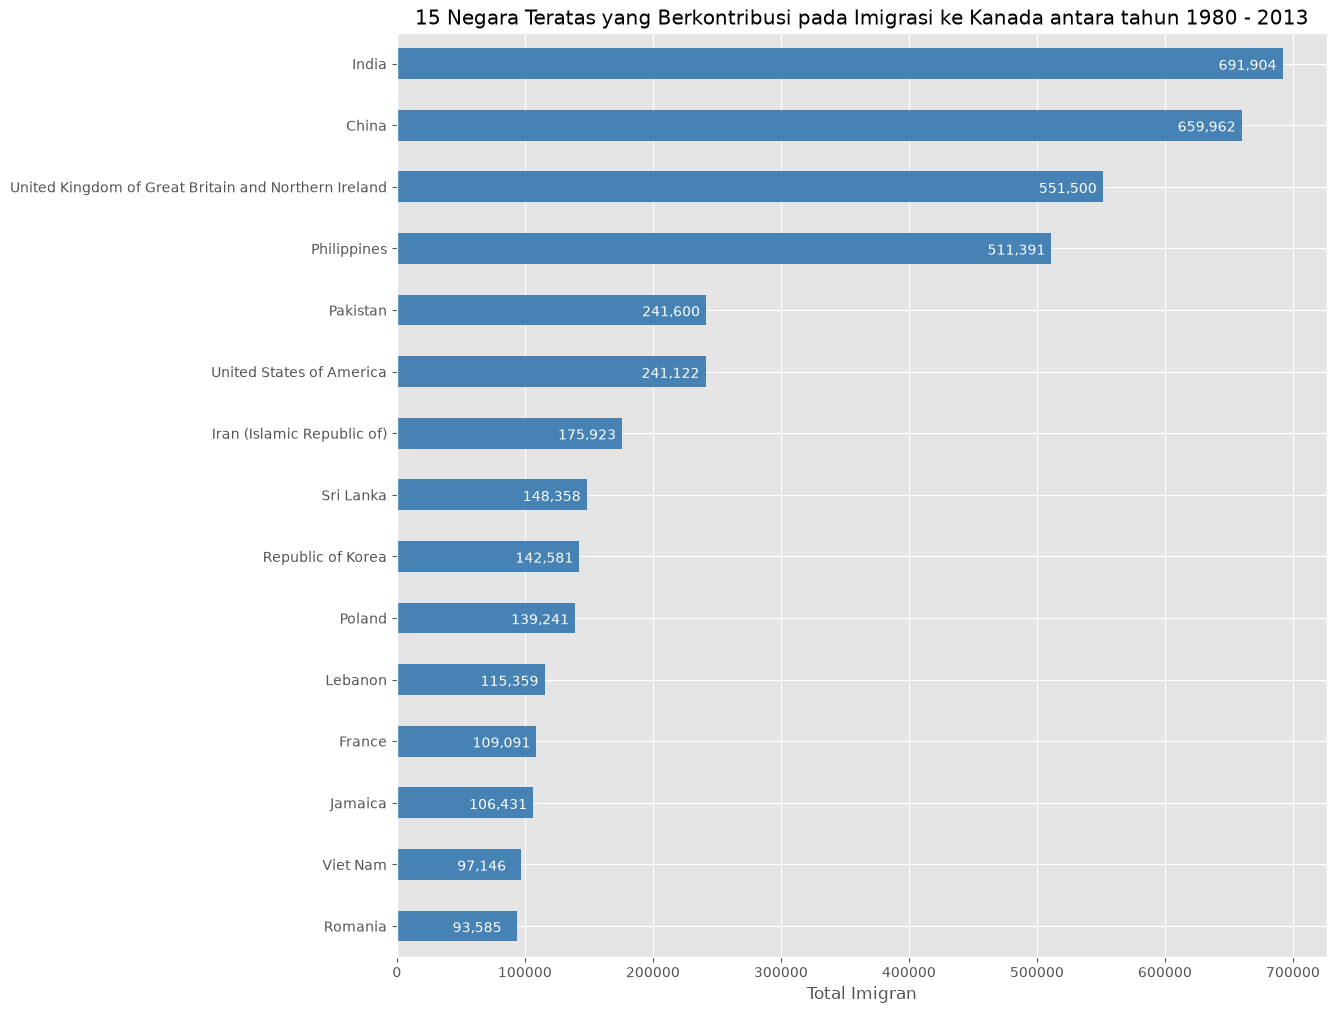

In [118]:
# Buat plot
df_top15.plot(kind="barh", figsize=(12, 12), color="steelblue")
plt.title("15 Negara Teratas yang Berkontribusi pada Imigrasi ke Kanada antara tahun 1980 - 2013")
plt.xlabel("Total Imigran")

# Berikan label nilai pada setiap negara.
for index, value in enumerate(df_top15):
    label = format(int(value), ",") # format int dengan koma

    # Letakkan teks di akhir batang (value/nominalnya dikurangi 50000, dan index dikurangi 0.1 (lebih ketengah) agar sesuai dengan batang)
    plt.annotate(label, xy=(value - 50000, index - 0.10), color="white")

plt.savefig("../outputs/barh_plot_15_top_country_with_annotate.png", dpi=200, bbox_inches="tight")
plt.show()